### 🔗 Live deployed app: PASTE-YOUR-STREAMLIT-LINK-HERE

# Used Car Price Prediction — Regression with 10-Fold Cross-Validation

**Name:** Ayesha Arif  
**Roll No:** FA24-BSE-028  
**Course:** Machine Learning Fundamentals (AIC354) — COMSATS University Islamabad, Lahore Campus  
**Dataset:** Used cars listing data from Kaggle (`used_cars.csv`, 4009 rows × 12 columns)  

**Goal:** predict the asking price (USD) of a used car from its brand, model, age, mileage, engine, transmission, colours, accident history and title status.

**Algorithms compared (5):** Extra Trees, Histogram Gradient Boosting, AdaBoost, Ridge Regression, Support Vector Regression.  
**Evaluation:** 10-fold cross-validation on the full dataset, scored with RMSE, MAE and R².

## Step 1 — Imports

In [1]:
import re, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor, AdaBoostRegressor
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42

## Step 2 — Load the dataset
In Google Colab the cell asks for `used_cars.csv`; when the file already sits next to the notebook it is read directly.

In [2]:
import os
if not os.path.exists("used_cars.csv"):
    try:
        from google.colab import files
        uploaded = files.upload()          # choose used_cars.csv
    except ImportError:
        raise FileNotFoundError("Place used_cars.csv in the same folder as this notebook.")

raw = pd.read_csv("used_cars.csv")
print("Shape:", raw.shape)
raw.head()

Shape: (4009, 12)


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


## Step 3 — Understand the data

In [3]:
raw.info()
print()
print("Missing values per column:")
print(raw.isna().sum()[raw.isna().sum() > 0])
print("\nDuplicate rows:", raw.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   brand         4009 non-null   str  
 1   model         4009 non-null   str  
 2   model_year    4009 non-null   int64
 3   milage        4009 non-null   str  
 4   fuel_type     3839 non-null   str  
 5   engine        4009 non-null   str  
 6   transmission  4009 non-null   str  
 7   ext_col       4009 non-null   str  
 8   int_col       4009 non-null   str  
 9   accident      3896 non-null   str  
 10  clean_title   3413 non-null   str  
 11  price         4009 non-null   str  
dtypes: int64(1), str(11)
memory usage: 892.6 KB

Missing values per column:
fuel_type      170
accident       113
clean_title    596
dtype: int64

Duplicate rows: 0


In [4]:
# Several columns are stored as text and need cleaning
for col in ["milage", "price", "engine", "transmission", "accident"]:
    print(f"{col:13s}", raw[col].dropna().sample(3, random_state=1).tolist())

milage        ['55,400 mi.', '87,500 mi.', '72,128 mi.']
price         ['$36,500', '$14,900', '$45,985']
engine        ['291.0HP 3.8L V6 Cylinder Engine Gasoline Fuel', '315.0HP 4.6L 8 Cylinder Engine Gasoline Fuel', '6.2L V8 16V MPFI SOHC Flexible Fuel']
transmission  ['8-Speed A/T', 'A/T', '6-Speed Automatic']
accident      ['None reported', 'At least 1 accident or damage reported', 'At least 1 accident or damage reported']


## Step 4 — Cleaning and feature extraction
- `price` (`$10,300`) and `milage` (`51,000 mi.`) are converted to numbers.
- `model_year` becomes **car_age** (2024 − year).
- The free-text `engine` column is split into **hp**, **liters** and **cylinders**.
- `transmission` is grouped into **transmission_type** (Automatic / Manual / CVT / Other) plus the number of **speeds**.
- `fuel_type` values `–` and `not supported` become `Unknown`; `accident` becomes *None reported / Reported / Unknown*; a missing `clean_title` is treated as `No`.
- Numeric gaps (e.g. electric cars have no cylinders) are filled with the median inside the pipeline, so nothing leaks from the validation folds.

In [5]:
REFERENCE_YEAR = 2024  # newest model year present in the data

CAT_COLS = ["brand", "model", "fuel_type", "transmission_type", "ext_col", "int_col", "accident", "clean_title"]
NUM_COLS = ["car_age", "milage", "hp", "liters", "cylinders", "speeds"]
FEATURES = CAT_COLS + NUM_COLS


def _num(pattern, text):
    m = re.search(pattern, str(text), flags=re.I)
    return float(m.group(1)) if m else np.nan


def _cylinders(text):
    m = re.search(r"\b[VIH](\d{1,2})\b|(\d{1,2})\s*Cylinder", str(text), flags=re.I)
    if not m:
        return np.nan
    return float(m.group(1) or m.group(2))


def _transmission_type(text):
    t = str(text).upper()
    if "CVT" in t:
        return "CVT"
    if "M/T" in t or "MANUAL" in t:
        return "Manual"
    if "A/T" in t or "AUTOMATIC" in t or "DUAL SHIFT" in t or "DCT" in t:
        return "Automatic"
    return "Other"


def _fuel(text):
    if pd.isna(text) or str(text).strip() in ("–", "-", "not supported"):
        return "Unknown"
    return str(text).strip()


def _accident(text):
    if pd.isna(text):
        return "Unknown"
    return "None reported" if "none" in str(text).lower() else "Reported"


def clean_cars(df):
    """Turn the raw Kaggle table into model-ready columns. Returns (X, y)."""
    out = pd.DataFrame(index=df.index)
    out["brand"] = df["brand"].str.strip()
    out["model"] = df["model"].str.strip()
    out["car_age"] = REFERENCE_YEAR - df["model_year"]
    out["milage"] = (df["milage"].astype(str).str.replace(r"[^\d.]", "", regex=True)
                     .replace("", np.nan).astype(float))
    out["fuel_type"] = df["fuel_type"].map(_fuel)
    out["hp"] = df["engine"].map(lambda s: _num(r"(\d+(?:\.\d+)?)\s*HP", s))
    out["liters"] = df["engine"].map(lambda s: _num(r"(\d+(?:\.\d+)?)\s*(?:L\b|Liter)", s))
    out["cylinders"] = df["engine"].map(_cylinders)
    out["transmission_type"] = df["transmission"].map(_transmission_type)
    out["speeds"] = df["transmission"].map(lambda s: _num(r"(\d+)-Speed", s))
    out["ext_col"] = df["ext_col"].astype(str).str.strip()
    out["int_col"] = df["int_col"].astype(str).str.strip()
    out["accident"] = df["accident"].map(_accident)
    out["clean_title"] = df["clean_title"].fillna("No")
    y = None
    if "price" in df.columns:
        y = (df["price"].astype(str).str.replace(r"[^\d.]", "", regex=True).astype(float))
    return out[FEATURES], y


In [6]:
X, y = clean_cars(raw)
print("Feature table:", X.shape)
display(X.head())
display(X[NUM_COLS].describe().T.round(2))

Feature table: (4009, 14)


,brand,model,fuel_type,transmission_type,ext_col,int_col,accident,clean_title,car_age,milage,hp,liters,cylinders,speeds
0,Ford,Utility Police Interceptor Base,E85 Flex Fuel,Automatic,Black,Black,Reported,Yes,11,51000.0,300.0,3.7,6.0,6.0
1,Hyundai,Palisade SEL,Gasoline,Automatic,Moonlight Cloud,Gray,Reported,Yes,3,34742.0,NaN,3.8,6.0,8.0
2,Lexus,RX 350 RX 350,Gasoline,Automatic,Blue,Black,None reported,No,2,22372.0,NaN,3.5,NaN,NaN
3,INFINITI,Q50 Hybrid Sport,Hybrid,Automatic,Black,Black,None reported,Yes,9,88900.0,354.0,3.5,6.0,7.0
4,Audi,Q3 45 S line Premium Plus,Gasoline,Automatic,Glacier White Metallic,Black,None reported,No,3,9835.0,NaN,2.0,4.0,8.0


,count,mean,std,min,25%,50%,75%,max
car_age,4009.0,8.48,6.10,0.00,4.0,7.0,12.0,50.0
milage,4009.0,64717.55,52296.60,100.00,23044.0,52775.0,94100.0,405000.0
hp,3201.0,332.21,122.26,70.00,248.0,310.0,400.0,1020.0
liters,3792.0,3.68,1.42,0.65,2.5,3.5,4.7,8.4
cylinders,3585.0,6.22,1.70,3.00,4.0,6.0,8.0,12.0
speeds,2156.0,6.83,1.87,1.00,6.0,7.0,8.0,10.0


## Step 5 — Explore the target
Prices are strongly right-skewed (a few luxury and exotic cars cost far more than the rest), so the models learn the **logarithm of price** and predictions are converted back to dollars before any metric is computed. All reported errors are therefore in real USD.

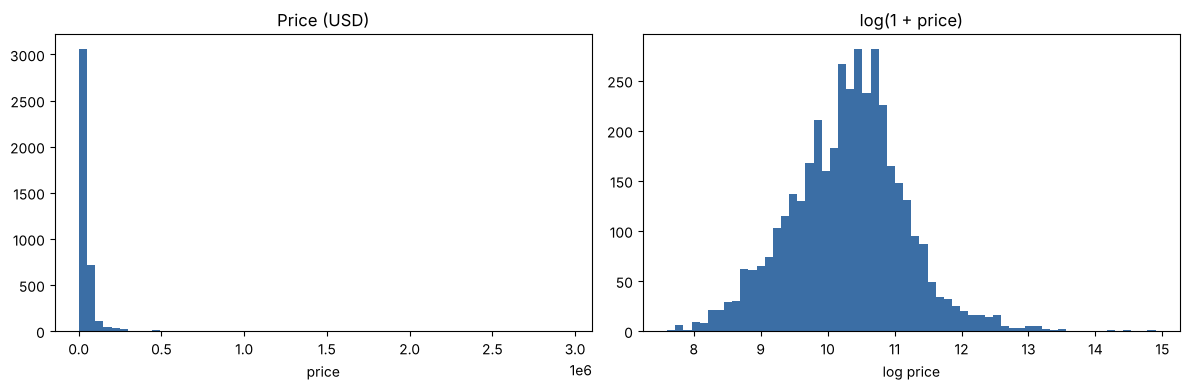

count       4009.0
mean       44553.0
std        78711.0
min         2000.0
25%        17200.0
50%        31000.0
75%        49990.0
max      2954083.0
Name: price, dtype: float64


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(y, bins=60, color="#3b6ea5"); ax[0].set_title("Price (USD)"); ax[0].set_xlabel("price")
ax[1].hist(np.log1p(y), bins=60, color="#3b6ea5"); ax[1].set_title("log(1 + price)"); ax[1].set_xlabel("log price")
plt.tight_layout(); plt.show()
print(y.describe().round(0))

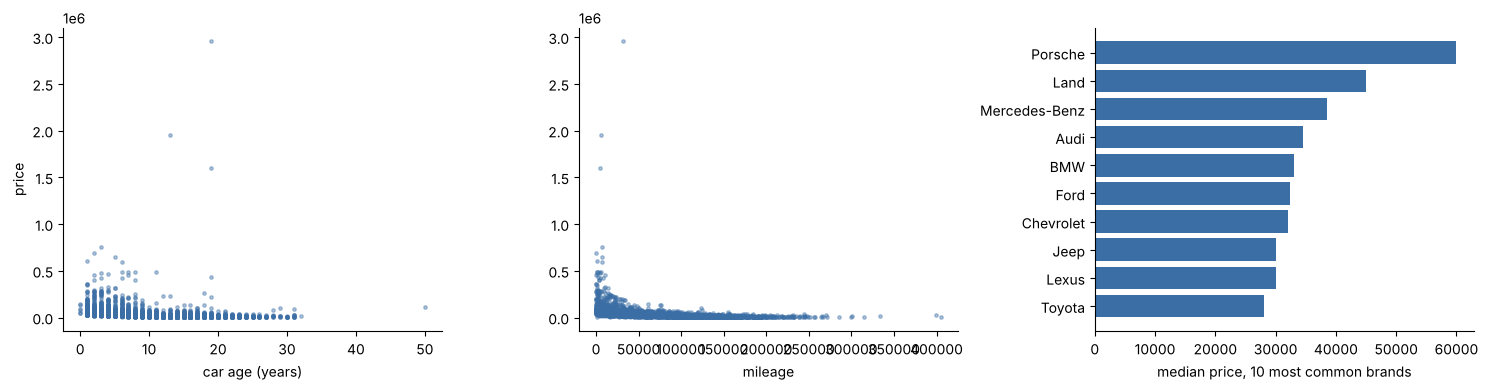

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(X["car_age"], y, s=6, alpha=.4, color="#3b6ea5"); ax[0].set_xlabel("car age (years)"); ax[0].set_ylabel("price")
ax[1].scatter(X["milage"], y, s=6, alpha=.4, color="#3b6ea5"); ax[1].set_xlabel("mileage")
top = X["brand"].value_counts().head(10).index
med = y.groupby(X["brand"]).median().loc[top].sort_values()
ax[2].barh(med.index, med.values, color="#3b6ea5"); ax[2].set_xlabel("median price, 10 most common brands")
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## Step 6 — Pipeline
Every model sits in the same pipeline: numeric columns are median-imputed and standardised, categorical columns are one-hot encoded (categories seen fewer than 5 times are grouped, unseen ones are ignored), and the regressor is wrapped so that it predicts `log(1 + price)` while returning dollars. The whole pipeline is fitted **inside each fold**, so the validation fold never influences preprocessing.

In [9]:
def make_pipeline(regressor):
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                          ("sc", StandardScaler())]), NUM_COLS),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5,
                              sparse_output=False), CAT_COLS),
    ])
    model = TransformedTargetRegressor(regressor=regressor, func=np.log1p, inverse_func=np.expm1)
    return Pipeline([("prep", pre), ("model", model)])

## Step 7 — The five regression algorithms

In [10]:
algorithms = {
    "Extra Trees": ExtraTreesRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300, random_state=RANDOM_STATE),
    "AdaBoost": AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE),
                                  n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE),
    "Ridge Regression": Ridge(alpha=3.0),
    "Support Vector Regression": SVR(kernel="rbf", C=10, epsilon=0.1),
}
for name, est in algorithms.items():
    print(f"{name:27s}{est}")

Extra Trees                ExtraTreesRegressor(n_estimators=300, n_jobs=-1, random_state=42)
Hist Gradient Boosting     HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300, random_state=42)
AdaBoost                   AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=8, random_state=42),
                  learning_rate=0.5, n_estimators=100, random_state=42)
Ridge Regression           Ridge(alpha=3.0)
Support Vector Regression  SVR(C=10)


## Step 8 — 10-fold cross-validation on the full dataset
The same ten shuffled folds are used for every algorithm, so the comparison is fair.

In [11]:
kf = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
folds = list(kf.split(X))

rows, oof = [], {name: np.zeros(len(y)) for name in algorithms}
fit_time = {name: 0.0 for name in algorithms}
for name, est in algorithms.items():
    for k, (tr, va) in enumerate(folds, start=1):
        t0 = time.time()
        pipe = clone(make_pipeline(est))
        pipe.fit(X.iloc[tr], y.iloc[tr])
        pred = pipe.predict(X.iloc[va])
        fit_time[name] += time.time() - t0
        oof[name][va] = pred
        rows.append({"Algorithm": name, "Fold": k,
                     "RMSE": np.sqrt(mean_squared_error(y.iloc[va], pred)),
                     "MAE": mean_absolute_error(y.iloc[va], pred),
                     "R2": r2_score(y.iloc[va], pred)})
    print(f"finished {name:27s} ({fit_time[name]:.0f}s)")
results = pd.DataFrame(rows)

finished Extra Trees                 (56s)


finished Hist Gradient Boosting      (24s)


finished AdaBoost                    (22s)


finished Ridge Regression            (1s)


finished Support Vector Regression   (17s)


## Step 9 — Results

**Fold-by-fold scores**

In [12]:
for metric in ["RMSE", "MAE", "R2"]:
    table = results.pivot(index="Fold", columns="Algorithm", values=metric)[list(algorithms)]
    print(f"\n{metric} per fold")
    display(table.style.format("{:.4f}" if metric == "R2" else "{:,.0f}")
            .background_gradient(cmap="Blues_r" if metric != "R2" else "Blues", axis=1))


RMSE per fold


Algorithm,Extra Trees,Hist Gradient Boosting,AdaBoost,Ridge Regression,Support Vector Regression
Fold,,,,,
1,"174,949","172,229","171,529","175,710","173,853"
2,"78,132","73,214","77,165","79,700","78,074"
3,"17,211","16,945","20,603","18,818","17,558"
4,"38,761","39,087","43,305","38,421","42,328"
5,"19,288","24,037","24,243","26,666","19,609"
6,"16,936","17,343","18,427","19,296","17,796"
7,"21,430","21,262","24,922","24,457","15,534"
8,"33,081","31,126","34,860","39,547","33,793"
9,"26,545","21,014","23,613","30,514","30,862"



MAE per fold


Algorithm,Extra Trees,Hist Gradient Boosting,AdaBoost,Ridge Regression,Support Vector Regression
Fold,,,,,
1,"19,734","19,847","22,139","21,628","19,664"
2,"11,565","12,279","14,095","14,127","12,186"
3,"7,980","8,003","10,157","9,056","8,089"
4,"10,217","10,706","12,265","12,153","11,346"
5,"8,091","9,427","10,082","10,682","8,864"
6,"6,710","7,123","8,593","8,809","7,286"
7,"8,281","9,085","10,981","9,994","7,955"
8,"10,330","11,118","12,063","13,674","11,267"
9,"8,502","8,478","9,925","10,775","9,783"



R2 per fold


Algorithm,Extra Trees,Hist Gradient Boosting,AdaBoost,Ridge Regression,Support Vector Regression
Fold,,,,,
1,0.0428,0.0724,0.0799,0.0345,0.0548
2,0.3120,0.3959,0.3290,0.2842,0.3131
3,0.8236,0.8290,0.7472,0.7891,0.8164
4,0.6579,0.6522,0.5730,0.6639,0.5921
5,0.8708,0.7994,0.7959,0.7531,0.8665
6,0.7880,0.7777,0.7491,0.7248,0.7660
7,0.7788,0.7823,0.7009,0.7119,0.8838
8,0.7405,0.7702,0.7118,0.6291,0.7292
9,0.7055,0.8154,0.7669,0.6108,0.6019


**Summary: mean ± standard deviation over the 10 folds**

In [13]:
summary = results.groupby("Algorithm").agg(
    RMSE_mean=("RMSE", "mean"), RMSE_std=("RMSE", "std"),
    MAE_mean=("MAE", "mean"), MAE_std=("MAE", "std"),
    R2_mean=("R2", "mean"), R2_std=("R2", "std")).loc[list(algorithms)]
summary["Pooled R2 (all folds)"] = [r2_score(y, oof[n]) for n in summary.index]
summary = summary.sort_values("RMSE_mean")
display(summary.style.format({"RMSE_mean": "{:,.0f}", "RMSE_std": "{:,.0f}", "MAE_mean": "{:,.0f}",
                              "MAE_std": "{:,.0f}", "R2_mean": "{:.4f}", "R2_std": "{:.4f}",
                              "Pooled R2 (all folds)": "{:.4f}"}))

,RMSE_mean,RMSE_std,MAE_mean,MAE_std,R2_mean,R2_std,Pooled R2 (all folds)
Algorithm,,,,,,,
Hist Gradient Boosting,"43,203","48,491","10,362","3,717",0.6766,0.2517,0.3568
Extra Trees,"44,379","49,483","9,953","3,721",0.6562,0.2678,0.3261
Support Vector Regression,"44,523","49,312","10,422","3,671",0.6494,0.2731,0.3265
AdaBoost,"45,659","47,693","11,966","3,920",0.6288,0.2413,0.3328
Ridge Regression,"47,277","48,611","12,083","3,806",0.6002,0.2477,0.2956


## Step 10 — Charts

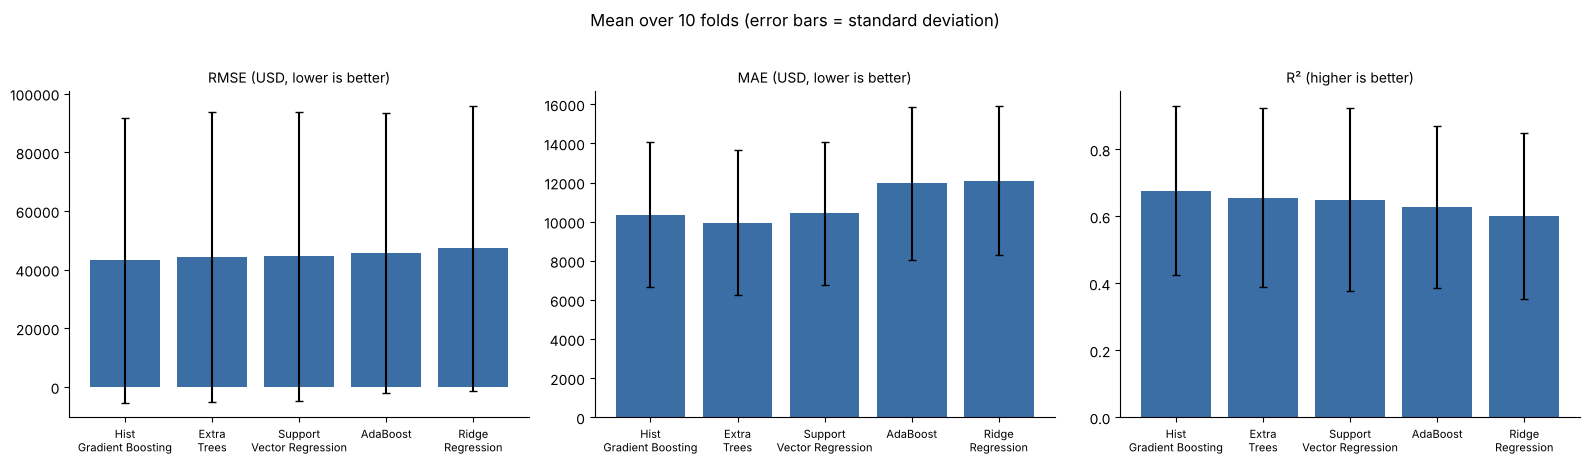

In [14]:
order = summary.index.tolist()
colors = ["#1f5fa8", "#5b9bd5", "#8fb8e0", "#c2d6ea", "#dce7f3"]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, (metric, label) in zip(ax, [("RMSE", "RMSE (USD, lower is better)"), ("MAE", "MAE (USD, lower is better)"), ("R2", "R² (higher is better)")]):
    m = results.groupby("Algorithm")[metric].mean().loc[order if metric != "R2" else summary.sort_values("R2_mean").index[::-1]]
    s = results.groupby("Algorithm")[metric].std().loc[m.index]
    a.bar(range(len(m)), m.values, yerr=s.values, capsize=3, color="#3b6ea5")
    a.set_xticks(range(len(m))); a.set_xticklabels([n.replace(" ", "\n", 1) for n in m.index], fontsize=8)
    a.set_title(label, fontsize=10); a.spines[["top", "right"]].set_visible(False)
plt.suptitle("Mean over 10 folds (error bars = standard deviation)", y=1.02)
plt.tight_layout(); plt.show()

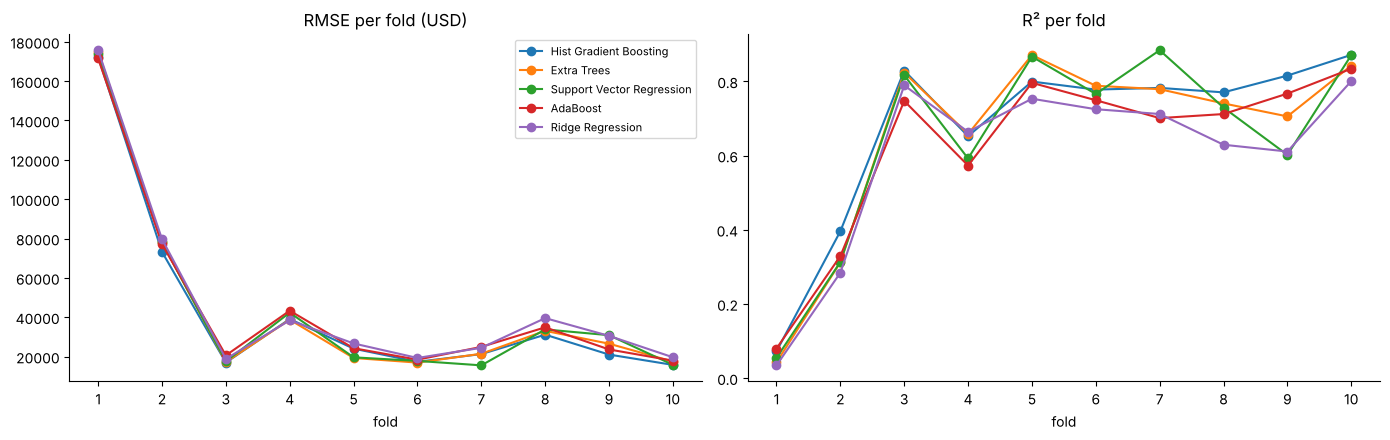

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for name in order:
    d = results[results.Algorithm == name]
    ax[0].plot(d.Fold, d.RMSE, marker="o", label=name)
    ax[1].plot(d.Fold, d.R2, marker="o", label=name)
ax[0].set_title("RMSE per fold (USD)"); ax[1].set_title("R² per fold")
for a in ax:
    a.set_xlabel("fold"); a.set_xticks(range(1, 11)); a.spines[["top", "right"]].set_visible(False)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Step 11 — Observations from the results

In [16]:
best = summary.index[0]
b = summary.loc[best]
print(f"Lowest mean RMSE : {best}  (RMSE {b.RMSE_mean:,.0f} USD, MAE {b.MAE_mean:,.0f} USD, R2 {b.R2_mean:.3f})")
print(f"Lowest mean MAE  : {summary.MAE_mean.idxmin()}")
print(f"Highest mean R2  : {summary.R2_mean.idxmax()}")
print(f"Most stable RMSE across folds (smallest std): {summary.RMSE_std.idxmin()}")
print(f"Worst RMSE       : {summary.index[-1]} ({summary.RMSE_mean.iloc[-1]:,.0f} USD)")
print("\nTotal training time over 10 folds (s):")
print(pd.Series(fit_time).round(1).sort_values().to_string())

Lowest mean RMSE : Hist Gradient Boosting  (RMSE 43,203 USD, MAE 10,362 USD, R2 0.677)
Lowest mean MAE  : Extra Trees
Highest mean R2  : Hist Gradient Boosting
Most stable RMSE across folds (smallest std): AdaBoost
Worst RMSE       : Ridge Regression (47,277 USD)

Total training time over 10 folds (s):
Ridge Regression              0.5
Support Vector Regression    17.4
AdaBoost                     22.1
Hist Gradient Boosting       23.6
Extra Trees                  56.0


**What the numbers show**

- **Hist Gradient Boosting** has the lowest mean RMSE (about \$43,200) and the highest mean R² (0.677), so it is selected as the final model. **Extra Trees** has the lowest mean MAE (about \$9,950), meaning it is slightly better on typical cars, while Hist Gradient Boosting handles the expensive cars better.
- **Support Vector Regression** and **Extra Trees** are close behind on RMSE; **AdaBoost** is in the middle; **Ridge Regression** is the weakest on every metric, because a linear model cannot capture how brand, model and age interact in pricing.
- The RMSE standard deviation (about \$48,000) is as large as the RMSE itself. The reason is a handful of extreme listings (the most expensive car is about \$2.95 million, while the median price is \$31,000). Whichever fold contains such a car gets a very large RMSE and a very low R², which is why the R² per fold ranges widely. MAE and the median error (about \$4,000, or 14 %) describe an ordinary car much better than RMSE does.
- The ranking of the five algorithms is the same for most of the folds, so the conclusion does not depend on one lucky split.
- Prices are log-transformed for training; errors are always reported in dollars.


## Step 12 — Predicted vs actual (out-of-fold predictions of the best model)
Every point below was predicted by a model that never saw that car.

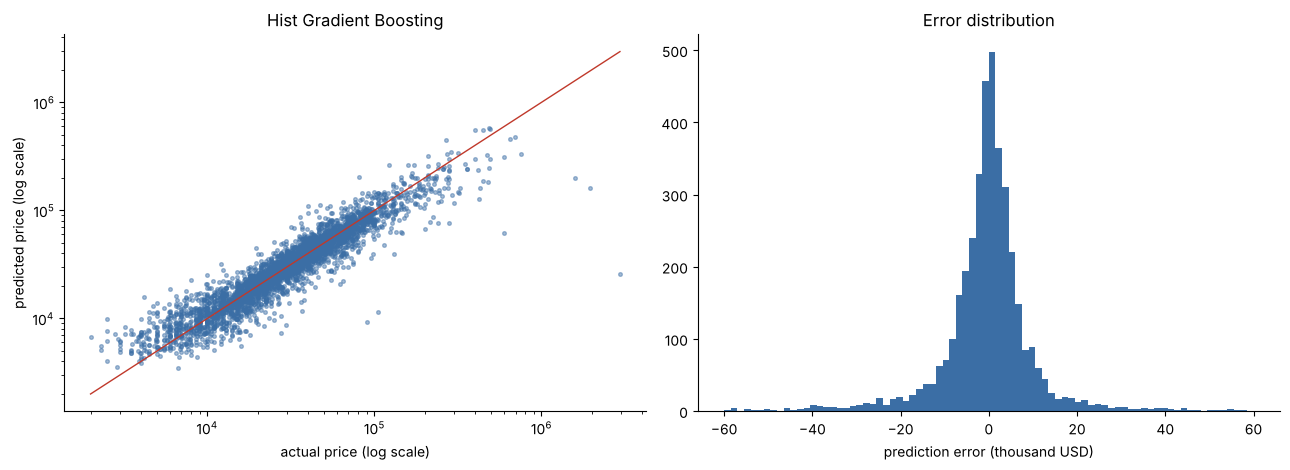

Median absolute error: 3,965 USD
Median absolute % error: 14.1 %


In [17]:
p = oof[best]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].scatter(y, p, s=7, alpha=.45, color="#3b6ea5")
lim = [y.min(), y.max()]; ax[0].plot(lim, lim, color="#c0392b", lw=1)
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("actual price (log scale)"); ax[0].set_ylabel("predicted price (log scale)"); ax[0].set_title(best)
ax[1].hist((p - y) / 1000, bins=80, range=(-60, 60), color="#3b6ea5")
ax[1].set_xlabel("prediction error (thousand USD)"); ax[1].set_title("Error distribution")
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
print("Median absolute error:", f"{np.median(np.abs(p - y)):,.0f} USD")
print("Median absolute % error:", f"{np.median(np.abs(p - y) / y) * 100:.1f} %")

## Step 13 — Train the final model and save it
The winning algorithm is refitted on all 4009 rows and stored together with its preprocessing in one file.

In [18]:
final_model = clone(make_pipeline(algorithms[best]))
final_model.fit(X, y)
joblib.dump(final_model, "used_car_price_model.joblib", compress=3)
print("Saved used_car_price_model.joblib  ->", round(os.path.getsize("used_car_price_model.joblib") / 1e6, 2), "MB")

# Reload and test on a brand-new car
loaded = joblib.load("used_car_price_model.joblib")
example = pd.DataFrame([{
    "brand": "Toyota", "model": "Camry LE", "fuel_type": "Gasoline", "transmission_type": "Automatic",
    "ext_col": "Black", "int_col": "Black", "accident": "None reported", "clean_title": "Yes",
    "car_age": 5, "milage": 45000, "hp": 203, "liters": 2.5, "cylinders": 4, "speeds": 8}])[FEATURES]
print(f"Predicted price for the example car: ${loaded.predict(example)[0]:,.0f}")

Saved used_car_price_model.joblib  -> 0.45 MB
Predicted price for the example car: $30,443


## Step 14 — Streamlit application
The saved model is served by `app.py` (repository files: `app.py`, `car_utils.py`, `used_car_price_model.joblib`, `used_cars.csv`, `requirements.txt`).  
The user picks the brand, model, year, mileage, engine and condition details; the app builds the same feature table used here and shows the estimated price.

```
pip install -r requirements.txt
streamlit run app.py
```

## Step 15 — Conclusion
Five regression algorithms were compared with 10-fold cross-validation on all 4009 cars. **Hist Gradient Boosting** gave the best RMSE and R², was refitted on the full dataset and saved as `used_car_price_model.joblib`, and is the model served by the Streamlit app linked at the top of this notebook.